# 02 · Modelagem, validação e interpretabilidade

Rode antes: `build_dataset`, `train`, `run_evaluation` e `factors` (veja o README).

In [1]:
import sys, warnings; warnings.filterwarnings("ignore")
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
from IPython.display import Image, display
from src.config import *
from src.preprocessing.build_dataset import carrega_gold, constroi, colunas_features
from src.visualization import plots
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
import json
M = json.loads((REPORTS / "metricas_finais.json").read_text())
R = json.loads((REPORTS / "resumo_avaliacao.json").read_text())
F = json.loads((REPORTS / "fatores_resumo.json").read_text())

## 1. Comparação de modelos (validação cruzada estratificada, 5 folds, só no treino)

In [2]:
cmp = pd.read_csv(REPORTS / "comparacao_modelos_cv.csv")
display(cmp.drop(columns="melhores_params").round(4))
print("modelo escolhido:", M["modelo"]); print(M["regra_selecao"])

,modelo,cv_roc_auc,cv_pr_auc,cv_f1,cv_accuracy,cv_roc_auc_std,cv_f1_std,train_roc_auc,gap_treino_cv
0,gradient_boosting,0.7456,0.7159,0.6372,0.6810,0.0180,0.0218,0.8254,0.0798
1,logreg,0.7416,0.6909,0.6496,0.6858,0.0135,0.0114,0.7618,0.0202
2,random_forest,0.7217,0.6912,0.5935,0.6655,0.0104,0.0216,0.7835,0.0617
3,dummy,0.5000,0.4609,0.0000,0.5391,0.0000,0.0000,NaN,NaN


modelo escolhido: logreg
1 erro-padrão: melhor CV=0.7456 (gradient_boosting), margem=0.0080; entre os candidatos dentro da margem, escolhido o de menor gap treino->CV


O Gradient Boosting tem a maior média de CV, mas a diferença para a Regressão Logística (≈0,004) é **menor que o erro-padrão** da validação. Pela regra do 1 erro-padrão, entre os modelos tecnicamente empatados escolhemos o de **menor distância treino→validação** (`gap_treino_cv`): a Regressão Logística (0,020, contra 0,080 do Gradient Boosting).

## 2. Desempenho no hold-out de teste (separado antes de qualquer ajuste)

,accuracy,precision_risco,recall_risco,f1_risco,roc_auc,pr_auc,brier
teste @0.5,0.6628,0.6432,0.6046,0.6233,0.7292,0.6943,0.2091
teste @0.40 (limiar via OOF),0.6543,0.5987,0.7598,0.6697,0.7292,0.6943,0.2091
treino @0.5,0.6946,0.6772,0.6449,0.6606,0.7598,0.7164,0.1985


,accuracy,f1_risco,roc_auc,pr_auc
dummy,0.5387,0.0000,0.5000,0.4613
logreg,0.6628,0.6233,0.7292,0.6943


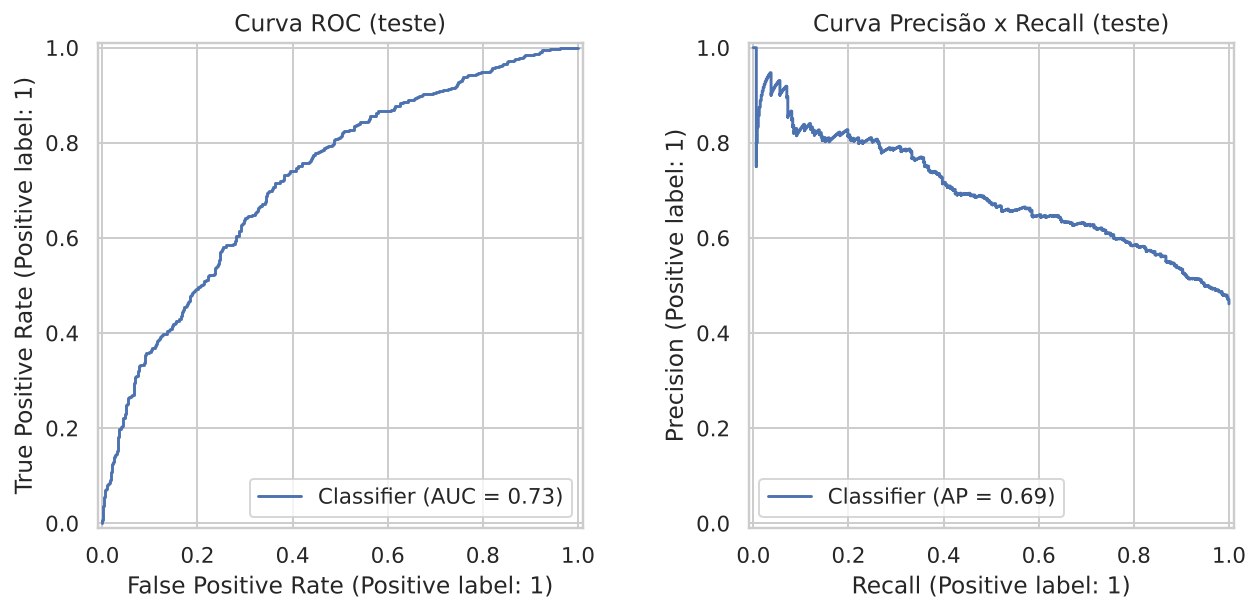

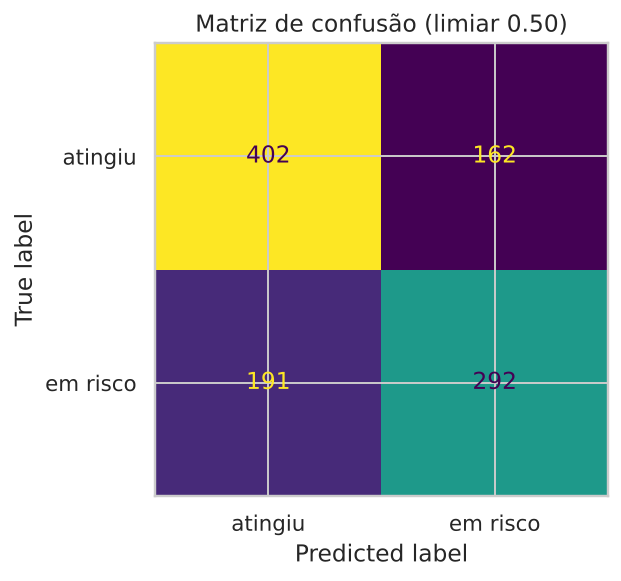

In [3]:
tab = pd.DataFrame({"teste @0.5": M["teste_limiar_0.5"], f"teste @{M['limiar_otimo_oof']:.2f} (limiar via OOF)": M["teste_limiar_otimo"],
                    "treino @0.5": M["treino_limiar_0.5"]}).T
display(tab[["accuracy", "precision_risco", "recall_risco", "f1_risco", "roc_auc", "pr_auc", "brier"]].round(4))
display(pd.DataFrame(M["baselines_teste"]).T[["accuracy", "f1_risco", "roc_auc", "pr_auc"]].round(4))
display(Image(str(IMAGES / "modelo_roc_pr.png"))); display(Image(str(IMAGES / "modelo_matriz_confusao.png")))

## 3. Generalização e overfitting

In [4]:
print("gap ROC-AUC treino - teste:", round(M["gap_roc_auc_treino_vs_teste"], 4))
print("CV aleatória (treino), modelo escolhido:", cmp[cmp.modelo == M["modelo"]][["cv_roc_auc", "cv_f1"]].round(4).to_dict("records")[0])
print("CV POR UF (estados não vistos):", {k: round(v, 4) for k, v in M["cv_por_uf_treino"].items()})

gap ROC-AUC treino - teste: 0.0306
CV aleatória (treino), modelo escolhido: {'cv_roc_auc': 0.7416, 'cv_f1': 0.6496}
CV POR UF (estados não vistos): {'roc_auc': 0.6379, 'pr_auc': 0.5907, 'f1': 0.5186, 'accuracy': 0.5867}


**Leitura honesta:** o gap treino↔teste é pequeno (0,031; era 0,138 na primeira versão, com UF e grades amplas). Quando o modelo é avaliado em **UFs que nunca viu**, o ROC-AUC é **0,638**, bem acima do 0,56 que tínhamos com a Gold sozinha, mas ainda abaixo da validação aleatória (0,742). Parte do ganho vem das fontes externas (SAEB, NSE, pobreza); a diferença restante é a política de metas de cada estado, que o modelo não enxerga sem a UF.

## 4. Interpretabilidade: Feature Importance, Permutation Importance e SHAP

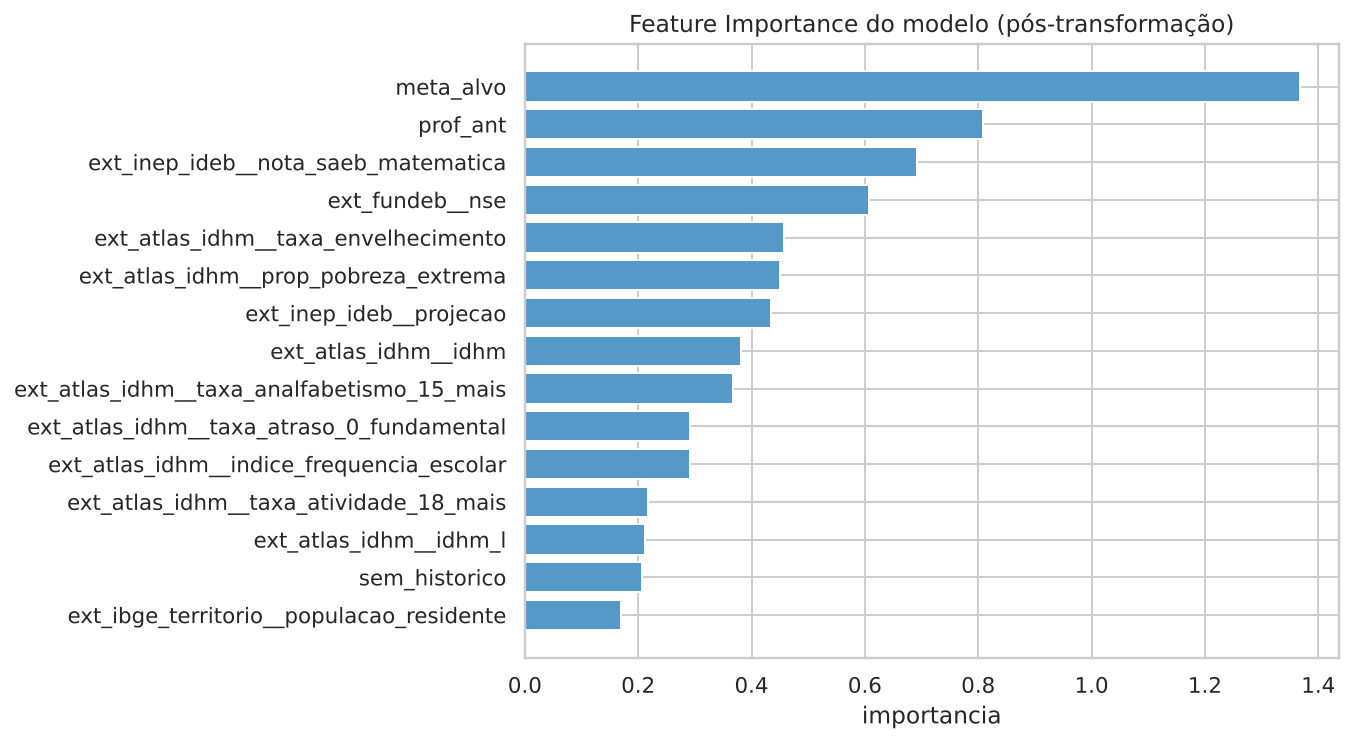

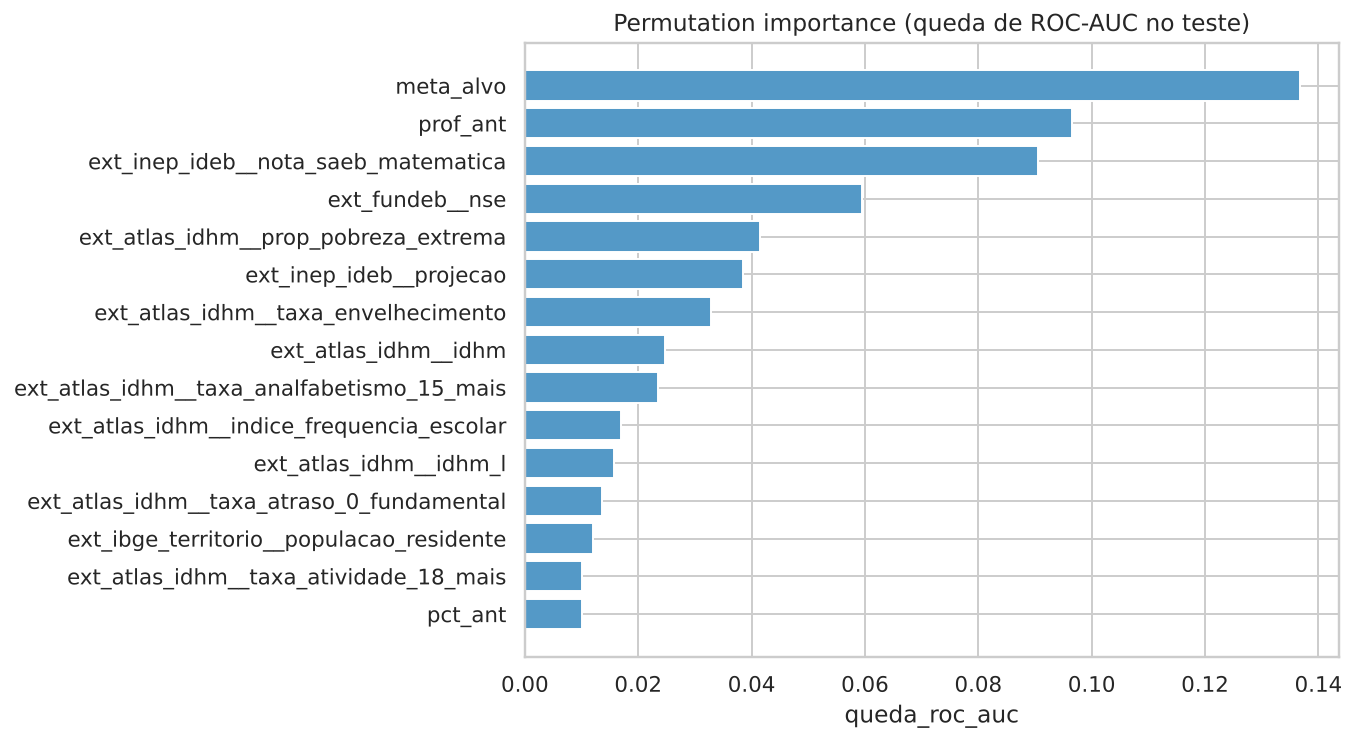

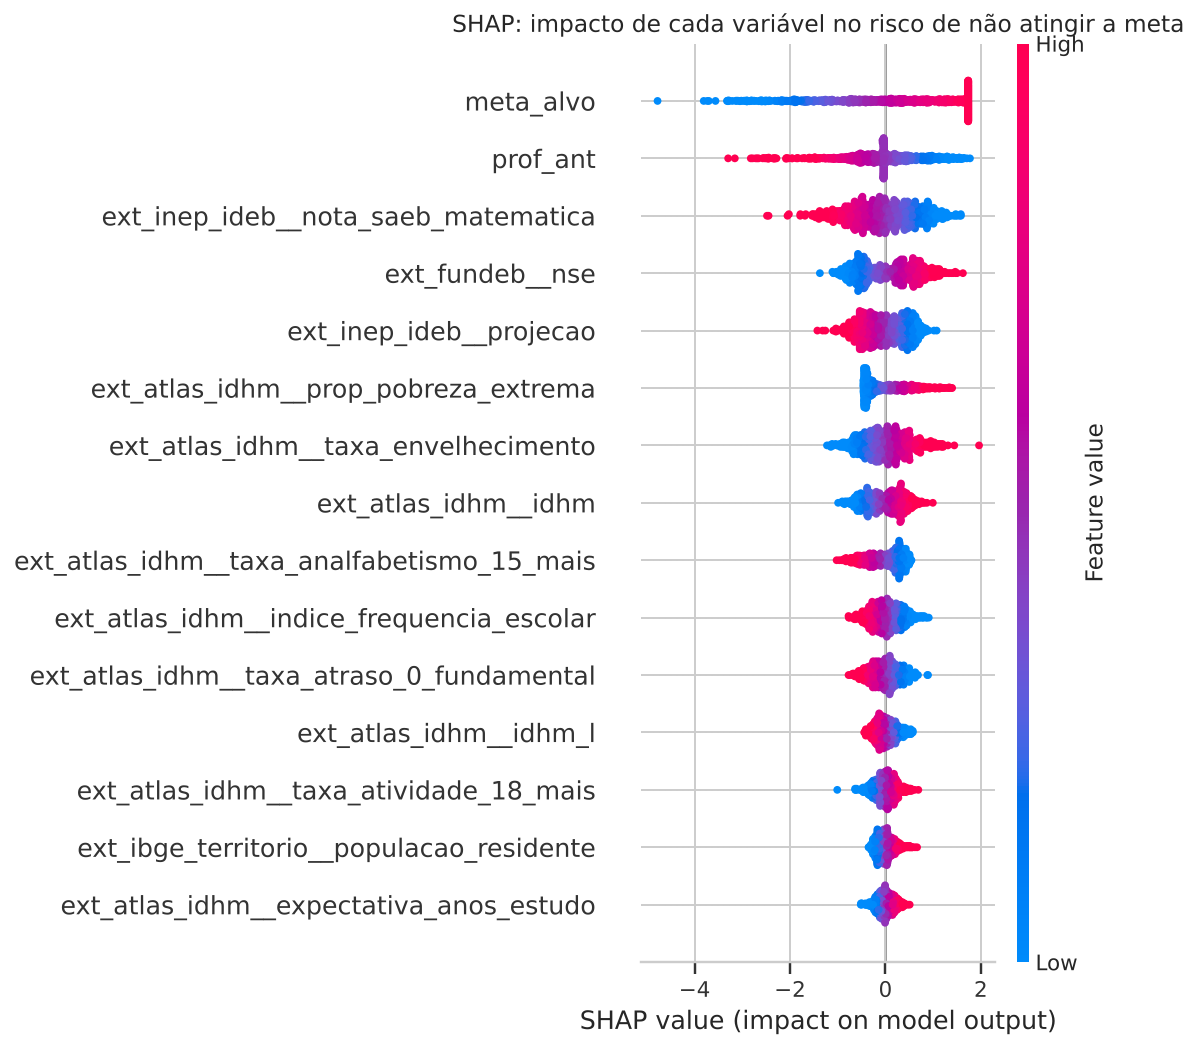

,feature,queda_roc_auc,desvio
0,meta_alvo,0.1367,0.0135
1,prof_ant,0.0965,0.0116
2,ext_inep_ideb__nota_saeb_matematica,0.0905,0.0092
3,ext_fundeb__nse,0.0595,0.0063
4,ext_atlas_idhm__prop_pobreza_extrema,0.0415,0.0079
5,ext_inep_ideb__projecao,0.0385,0.0068
6,ext_atlas_idhm__taxa_envelhecimento,0.0328,0.0099
7,ext_atlas_idhm__idhm,0.0248,0.0056


In [5]:
for f in ["modelo_importancia_nativa.png", "modelo_importancia_permutacao.png", "shap_summary.png"]:
    display(Image(str(IMAGES / f)))
display(pd.read_csv(REPORTS / "importancia_permutacao.csv").head(8).round(4))

`meta_alvo` e `prof_ant` lideram nas três medidas. Em seguida vêm **nota de matemática do SAEB**, **NSE do FUNDEB**, **pobreza extrema** e **envelhecimento** (Atlas). O contexto socioeconômico aparece, mas como complemento ao histórico e à meta.

## 5. Municípios de maior risco

In [6]:
risco = pd.read_csv(REPORTS / "risco_municipios_2024.csv")
display(risco.head(15).round(3))
display(pd.read_csv(REPORTS / "risco_por_uf.csv").head(10))

,id_municipio,nome_municipio,sigla_uf,regiao,pct_ant,meta_alvo,pct_alvo,risco_nao_atingir_meta,prob_risco
0,4313391,Novo Cabrais,RS,Sul,86.078,80.00,76.964,1,1.000
1,4318499,São José do Inhacorá,RS,Sul,82.480,80.00,49.667,1,1.000
2,4306130,Cruzaltense,RS,Sul,77.778,78.11,64.286,1,0.999
3,4320578,Sete de Setembro,RS,Sul,78.571,78.78,66.667,1,0.998
4,4212650,Pescaria Brava,SC,Sul,40.366,46.60,45.952,1,0.997
5,4320453,Sério,RS,Sul,85.413,80.00,11.111,1,0.997
6,4306551,Dom Pedro de Alcântara,RS,Sul,95.454,80.00,57.143,1,0.996
7,4321493,Toropi,RS,Sul,100.000,80.00,38.656,1,0.996
8,4220000,Balneário Rincão,SC,Sul,52.643,55.22,51.642,1,0.996
9,4315149,Presidente Lucena,RS,Sul,87.035,80.00,57.679,1,0.996


,sigla_uf,municipios,risco_medio,pct_em_risco_real,pct_prob_acima_70
0,PA,136,0.677,0.662,0.478
1,RS,421,0.668,0.917,0.496
2,AP,16,0.663,0.625,0.375
3,RJ,90,0.638,0.600,0.411
4,AM,48,0.610,0.604,0.375
5,PE,184,0.555,0.391,0.217
6,BA,394,0.555,0.810,0.246
7,RO,52,0.531,0.481,0.173
8,SC,238,0.527,0.458,0.155
9,PR,395,0.524,0.532,0.172


As probabilidades vêm de predição *out-of-fold*: nenhum município é previsto por um modelo que viu o próprio rótulo. **Atenção:** sem a UF, o modelo subestima estados com metas rígidas (ex.: RS tem 92% de municípios realmente em risco, e o risco médio previsto é 0,67).

## 6. Regiões com padrões semelhantes (K-Means)

,Unnamed: 0,silhouette
0,2,0.287917
1,3,0.137991
2,4,0.111270
3,5,0.117967
4,6,0.124245
5,7,0.103456
6,8,0.096490


grupo,0,1
n_municipios,3046.00,2186.00
taxa_risco,0.44,0.49
pct_ant,69.08,49.26
pct_alvo,69.52,53.63
meta_alvo,68.92,54.02
ext_atlas_idhm__idhm,0.71,0.59
ext_atlas_idhm__renda_pc,619.41,264.08
ext_atlas_idhm__prop_pobreza,8.10,41.45
ext_fundeb__nse,54.41,41.58
ext_inep_ideb__nota_saeb_matematica,232.07,202.10


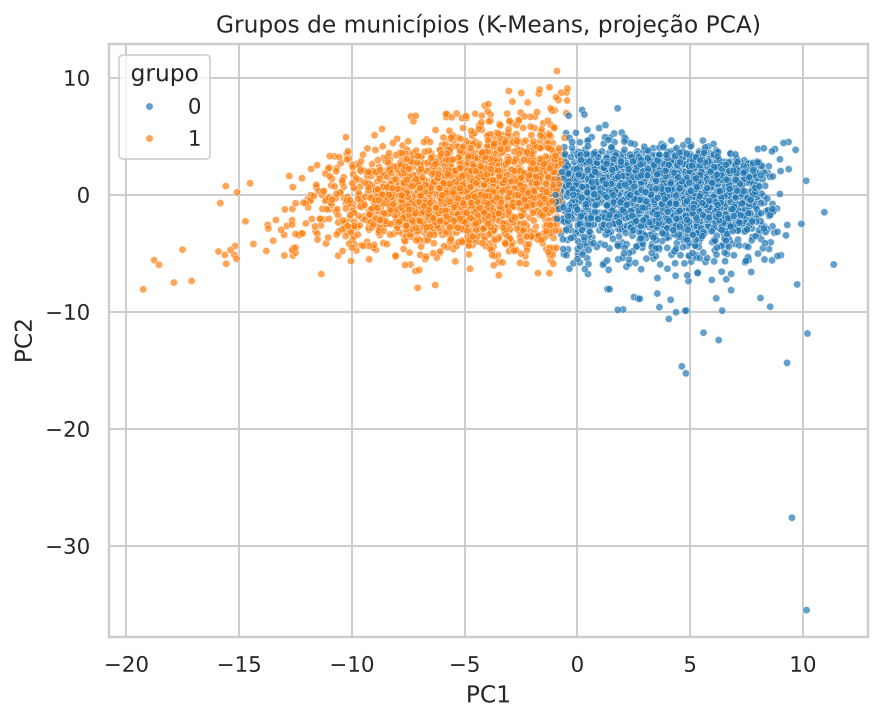

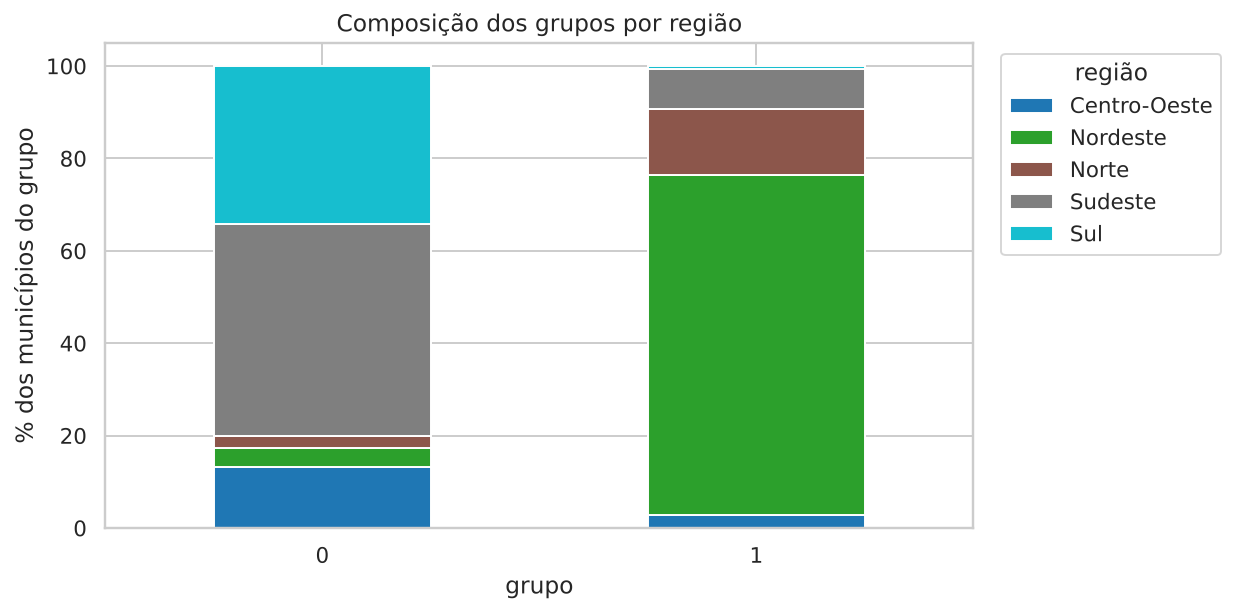

In [7]:
display(pd.read_csv(REPORTS / "silhouette_por_k.csv"))
perfil = pd.read_csv(REPORTS / "perfil_grupos.csv").set_index("grupo")
display(perfil[["n_municipios", "taxa_risco", "pct_ant", "pct_alvo", "meta_alvo", "ext_atlas_idhm__idhm",
                "ext_atlas_idhm__renda_pc", "ext_atlas_idhm__prop_pobreza", "ext_fundeb__nse",
                "ext_inep_ideb__nota_saeb_matematica"]].T.round(2))
display(Image(str(IMAGES / "cluster_pca.png"))); display(Image(str(IMAGES / "cluster_composicao_regiao.png")))

Os grupos separam **contexto**, não risco: o grupo 0 (3.046 municípios, 46% Sudeste, 34% Sul) tem IDHM 0,71 e pobreza de 8%; o grupo 1 (2.186, 74% Nordeste) tem IDHM 0,59 e pobreza de 41%. A taxa de risco é parecida (44% vs 49%) porque as metas do grupo 1 são mais baixas. O silhouette (0,288) indica estrutura fraca: tratamos como **segmentação grosseira**, não como tipologia.

## 7. Municípios que podem não atingir metas futuras (2025)

In [8]:
print(R["projecao"])
proj = pd.read_csv(REPORTS / "projecao_risco_meta_2025.csv")
print("municípios com prob. > 70%:", int((proj.prob_risco_proxima_meta > 0.7).sum()), "de", len(proj))
display(proj.head(15).round(3))

projeção 2025 gerada para 5352 municípios
municípios com prob. > 70%: 1458 de 5352


,id_municipio,nome_municipio,sigla_uf,pct_ant,meta_alvo,prob_risco_proxima_meta
0,4318499,São José do Inhacorá,RS,49.667,80.00,1.000
1,4321493,Toropi,RS,38.656,80.00,1.000
2,4320453,Sério,RS,11.111,80.00,1.000
3,4313391,Novo Cabrais,RS,76.964,80.00,1.000
4,4304853,Carlos Gomes,RS,50.000,62.87,0.999
5,4306551,Dom Pedro de Alcântara,RS,57.143,80.00,0.999
6,4315149,Presidente Lucena,RS,57.679,80.00,0.999
7,4320578,Sete de Setembro,RS,66.667,78.99,0.998
8,4212650,Pescaria Brava,SC,45.952,52.93,0.998
9,4306130,Cruzaltense,RS,64.286,78.43,0.998


A projeção usa o desempenho de 2024 como base e as metas oficiais de 2025. Pressupõe que a relação aprendida em 2023→2024 se mantém: é um alerta, não uma previsão garantida.

## 8. Fatores associados ao nível de alfabetização (regressão)

,variante,modelo,n_variaveis,r2_cv,r2_por_uf,r2_treino,r2_teste,mae_teste_pp
0,contexto,ridge,66,0.437,0.028,0.455,0.408,11.442
1,contexto,gradient_boosting,66,0.492,0.017,0.684,0.487,10.419
2,contexto_sem_desempenho,ridge,59,0.262,-0.299,0.282,0.248,13.379
3,contexto_sem_desempenho,gradient_boosting,59,0.367,-0.213,0.601,0.356,12.106
4,contexto_mais_historico,ridge,68,0.532,0.121,0.547,0.525,10.218
5,contexto_mais_historico,gradient_boosting,68,0.578,0.174,0.733,0.574,9.532


contexto -> [('inep_ideb__nota_saeb_matematica', 0.339), ('fundeb__nse', 0.051), ('inep_ideb__taxa_aprovacao', 0.046), ('inep_alunos_avaliados__qtd_alunos_avaliados', 0.024), ('atlas_idhm__taxa_energia_eletrica', 0.022)]
contexto_sem_desempenho -> [('atlas_idhm__indice_frequencia_escolar', 0.112), ('atlas_idhm__taxa_analfabetismo_11_a_14', 0.1), ('fundeb__nse', 0.061), ('atlas_idhm__taxa_analfabetismo_15_mais', 0.037), ('atlas_idhm__taxa_energia_eletrica', 0.035)]


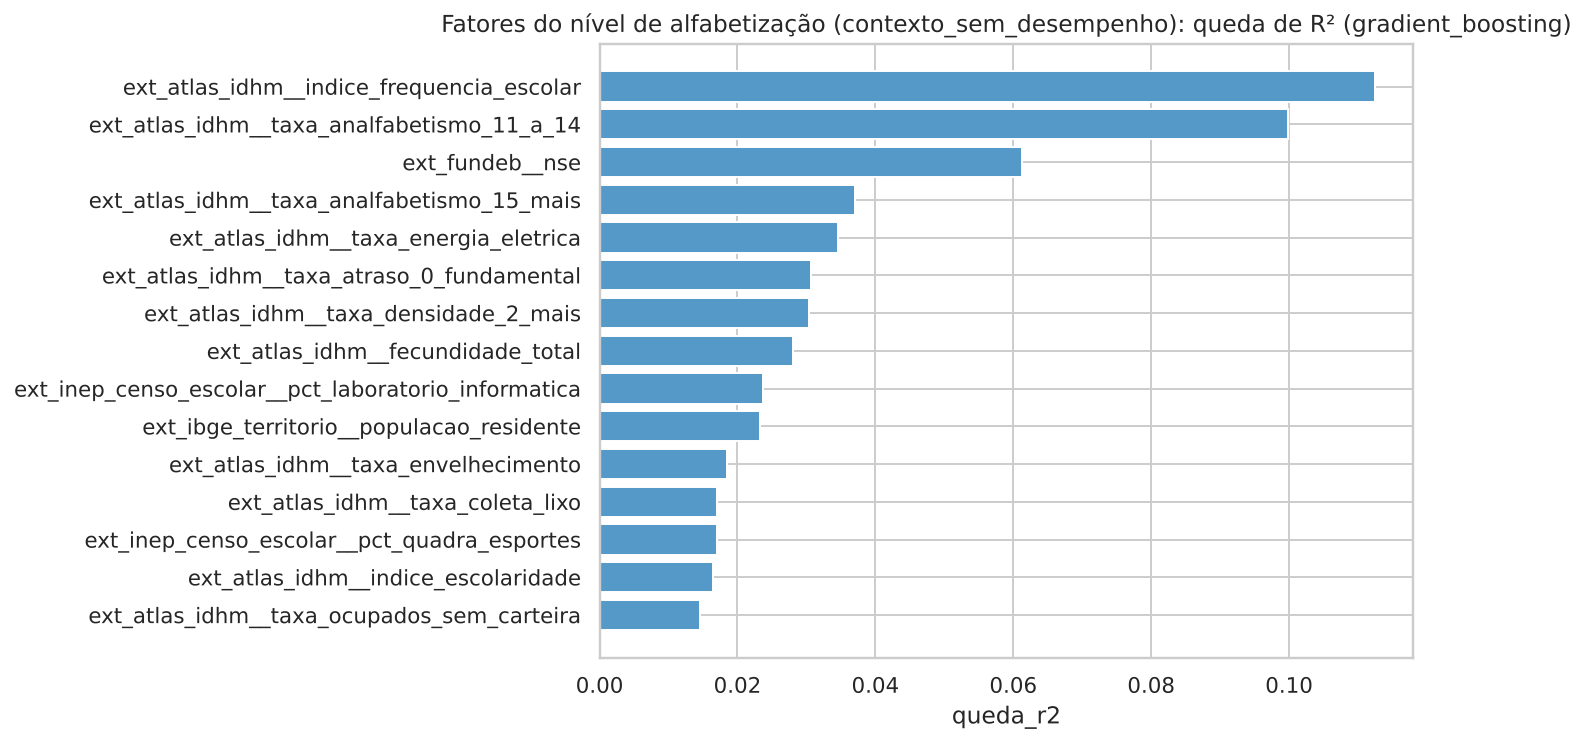

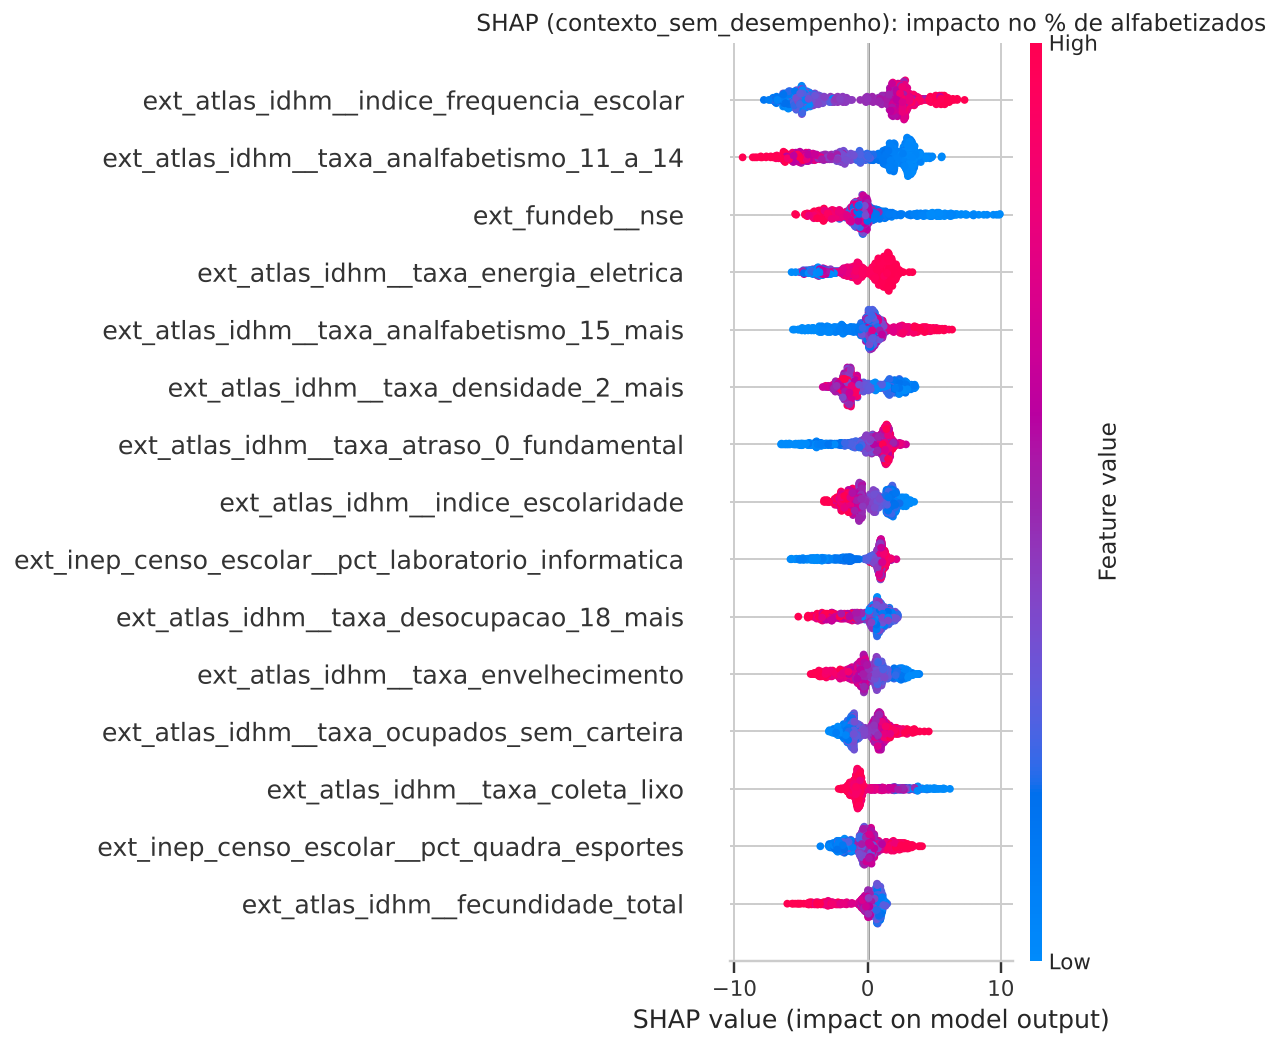

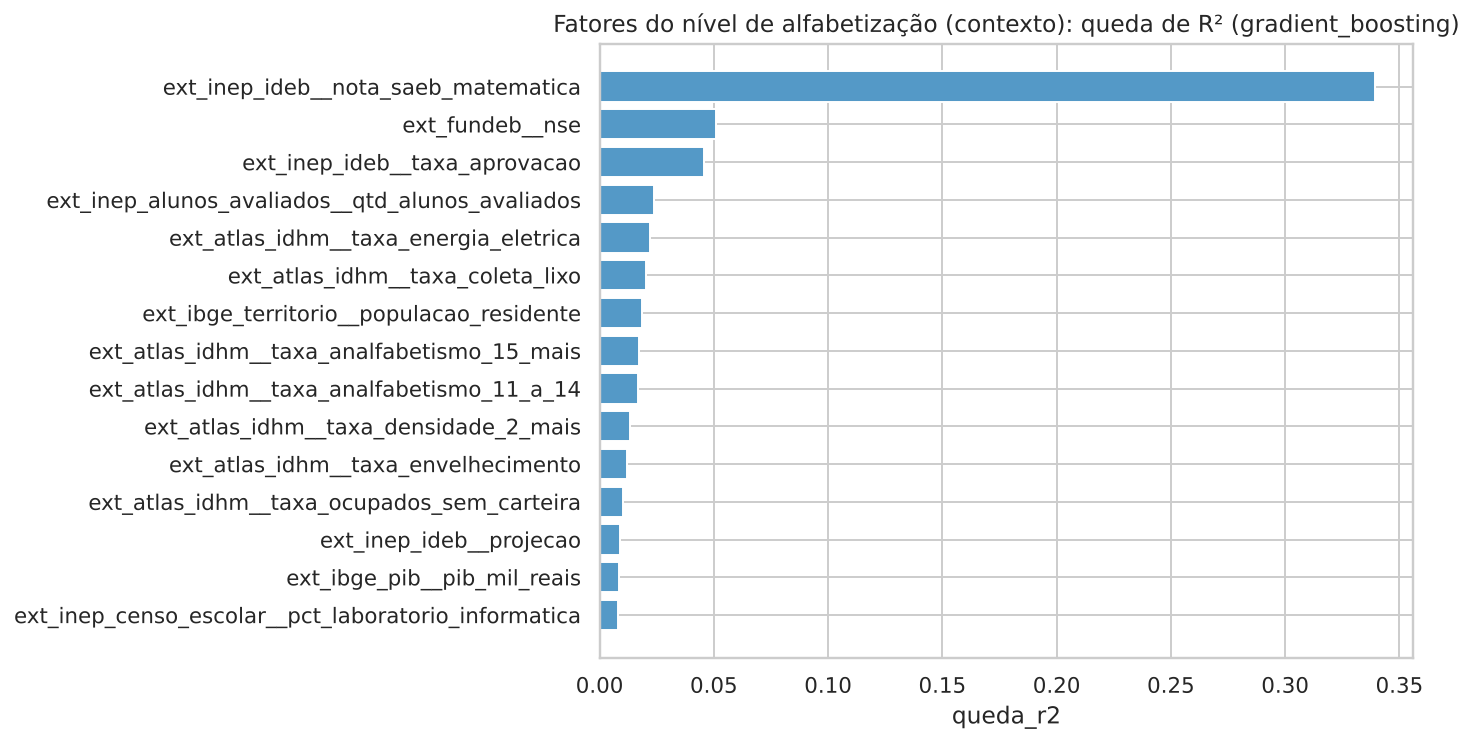

In [9]:
comp = pd.read_csv(REPORTS / "fatores_comparacao.csv")
display(comp[["variante", "modelo", "n_variaveis", "r2_cv", "r2_por_uf", "r2_treino", "r2_teste", "mae_teste_pp"]].round(3))
for v in ["contexto", "contexto_sem_desempenho"]:
    print(v, "->", [(d["feature"].replace("ext_", ""), round(d["queda_r2"], 3)) for d in F[v]["top5_fatores"]])
for f in ["fatores_importancia_permutacao_contexto_sem_desempenho.png", "fatores_shap_summary_contexto_sem_desempenho.png",
          "fatores_importancia_permutacao_contexto.png"]:
    display(Image(str(IMAGES / f)))

**Como ler:**
- Com todo o contexto, a nota de matemática do SAEB explica sozinha 0,34 de R², mas é **outro indicador de aprendizagem**, então não é um "fator" no sentido de política.
- **Sem IDEB/SAEB**, o contexto explica R²≈0,37 (CV): os fatores principais são **frequência escolar, analfabetismo de 11–14 anos e de 15+ (Atlas), NSE (FUNDEB) e infraestrutura domiciliar (energia)**.
- Com o histórico de 2023 (`contexto_mais_historico`), R²≈0,58.
- **Limite importante:** o R² por UF (treinando em alguns estados e testando em outros) é ≈0 ou negativo para as variantes de contexto: as relações valem *dentro* da amostra, mas não se transferem de forma estável entre estados. Os Atlas são do Censo 2010. **São associações, não causas.**